# Обучение CatBoost и динамической Ridge

Финальная модель CatBoost обучается на всех очищенных данных 2023–2026 годов. Год 2026 — базовый год, для которого строится начальная оценка. Динамическая Ridge задаёт годовые темпы изменения цены на выбранном горизонте. Перед финальным обучением качество проверяется на исторических периодах без утечки будущих данных.

jupyter notebook

## 1. Библиотеки и пути к данным

Ячейка находит корень проекта по исходному CSV, подключает функции приложения для подготовки данных и задаёт путь, по которому будет сохранён файл моделей.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import joblib
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Ridge
from catboost import CatBoostRegressor

ROOT = Path.cwd()
CSV_NAME = "СДЕЛКИ_Мос_2023-2026.csv"
while not (ROOT / CSV_NAME).exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / CSV_NAME).exists():
    raise FileNotFoundError("Source CSV was not found in the project root")
sys.path.insert(0, str(ROOT / "web_app"))
import model as app_model

DATA_PATH = ROOT / CSV_NAME
BUNDLE_PATH = ROOT / "Prognosis_model.joblib"
RANDOM_STATE = 42
CAT_COLS = ["region", "district", "street", "wall_material_code"]
NUM_COLS = ["year_build", "floor", "area"]
FEATURE_COLS = CAT_COLS + NUM_COLS + ["period_year"]
FINAL_BASE_YEAR = 2026
print("Project root:", ROOT)
print("Data file:", DATA_PATH)
print("Bundle path:", BUNDLE_PATH)

Project root: C:\Users\AnnaA\Desktop\Prognosis_system
Data file: C:\Users\AnnaA\Desktop\Prognosis_system\СДЕЛКИ_Мос_2023-2026.csv
Bundle path: C:\Users\AnnaA\Desktop\Prognosis_system\Prognosis_model.joblib


## 2. Гиперпараметры моделей

Фиксируются лучшие параметры из сравнительного исследования: CatBoost выбран по минимальному MAE временной кросс-валидации; для динамической Ridge используются лучшие параметры временной модели.


In [2]:
CATBOOST_PARAMS = {
    "iterations": 555,
    "depth": 10,
    "learning_rate": 0.056794,
    "l2_leaf_reg": 2.0917992640459695,
    "random_strength": 0.5598053604013576,
    "cat_feature_mode": "native",
    "year_weighting": "none",
}
RIDGE_PARAMS = {"alpha": 200.0, "trend_scale": 0.75}
print("CatBoost:", CATBOOST_PARAMS)
print("Dynamic Ridge:", RIDGE_PARAMS)

CatBoost: {'iterations': 555, 'depth': 10, 'learning_rate': 0.056794, 'l2_leaf_reg': 2.0917992640459695, 'random_strength': 0.5598053604013576, 'cat_feature_mode': 'native', 'year_weighting': 'none'}
Dynamic Ridge: {'alpha': 200.0, 'trend_scale': 0.75}


## 3. Подготовка обучающей выборки

Применяются те же очистка и фильтры, что и в приложении. Финальный CatBoost обучается на всей очищенной выборке, включая 2026 год. Для исторического backtest 2026 год станет отложенной проверкой; его записи не попадут в обучение backtest.

In [3]:
df_raw = app_model.read_csv_robust(DATA_PATH)
df_raw.columns = df_raw.columns.astype(str).str.strip().str.lower()
clean_df = app_model.clean_data(df_raw)
# Финальный набор готовится приложением по её производственной схеме.
model_df = app_model._prepare_model_data(clean_df)
if model_df.empty or model_df["period_year"].max() < FINAL_BASE_YEAR:
    raise ValueError("В очищенной выборке должны присутствовать сделки за 2026 год")
print(f"Строк финального обучения: {len(model_df):,}")
display(model_df.groupby("period_year").agg(deals=("price", "size"), median_price=("price", "median")))

Строк финального обучения: 60,289


,deals,median_price
period_year,,
2023,2999,23538610.0
2024,18148,23603680.0
2025,23702,23500000.0
2026,15440,22000000.0


## 4. Определение алгоритмов и признаков

Здесь объявляется оценщик `ApartmentEstimator` из сравнительного ноутбука. Он строит признаки квартиры, обучает CatBoost или Ridge на логарифме цены за квадратный метр и переводит результат обратно в полную цену.


In [4]:
from sklearn.linear_model import Ridge
from sklearn.feature_extraction import DictVectorizer
from sklearn.ensemble import HistGradientBoostingRegressor
from catboost import CatBoostRegressor

TIME_CENTER = 2024.5
MIN_STREET_TOTAL, MIN_STREET_PER_YEAR = 20, 5
MIN_DISTRICT_TOTAL, MIN_DISTRICT_PER_YEAR = 15, 3
MODEL_NAMES = {
    'ridge_static':'Статическая гедоническая Ridge',
    'ridge_time':'Динамическая гедоническая Ridge',
    'hgb':'HistGradientBoosting',
    'cat':'CatBoost'
}

def district_key(r):
    return f"{r['region']} | {r['district']}"

def street_key(r):
    return f"{r['region']} | {r['district']} | {r['street']}"

def supported_keys(frame, key_func, minimum_total, minimum_year):
    keys=[key_func(row) for row in frame[CAT_COLS].to_dict('records')]
    count=pd.crosstab(pd.Series(keys, index=frame.index), frame['period_year'])
    keep=(count.sum(axis=1)>=minimum_total) & ((count>=minimum_year).sum(axis=1)>=2)
    return set(count.index[keep])

def make_support(frame):
    return {
        'district_trends':supported_keys(frame,district_key,MIN_DISTRICT_TOTAL,MIN_DISTRICT_PER_YEAR),
        'street_trends':supported_keys(frame,street_key,MIN_STREET_TOTAL,MIN_STREET_PER_YEAR)
    }

def record_features(row, support, with_time=True, trend_scale=1.0):
    region=str(row['region']); wall=str(row['wall_material_code'])
    dist=district_key(row); street=street_key(row)
    log_area=np.log(float(row['area'])/50.0)
    floor=(float(row['floor'])-7)/12.0
    build=(float(row['year_build'])-1985)/40.0
    numeric={'log_area':log_area,'log_area_sq':log_area**2,
             'floor':floor,'floor_sq':floor**2,'build':build,'build_sq':build**2}
    level={'region='+region:1.,'district='+dist:1.,'street='+street:1.,'wall='+wall:1.,**numeric}
    features={'L:'+k:v for k,v in level.items()}
    if with_time:
        slope={'global':1.,'region='+region:1.,'wall='+wall:1.,**numeric}
        if dist in support['district_trends']:
            slope['district='+dist]=1.
        if street in support['street_trends']:
            slope['street='+street]=1.
        t=(float(row['period_year'])-TIME_CENTER)*float(trend_scale)
        features.update({'T:'+k:t*v for k,v in slope.items()})
    return features

def metrics(y, pred):
    y=np.asarray(y,float); pred=np.asarray(pred,float)
    mae=float(mean_absolute_error(y,pred)/1e6)
    rmse=float(np.sqrt(mean_squared_error(y,pred))/1e6)
    mape=float(np.mean(np.abs(y-pred)/y)*100)
    return {'MAE, млн ₽':mae,'RMSE, млн ₽':rmse,'R²':float(r2_score(y,pred)),
            'MAPE, %':mape,'Точность, %':100-mape}

class ApartmentEstimator(RegressorMixin, BaseEstimator):
    """Единый sklearn-совместимый интерфейс; преобразования обучаются внутри CV-fold."""
    def __init__(self, kind='ridge_time', alpha=100.0, trend_scale=1.0,
                 max_iter=180, max_leaf_nodes=31, min_samples_leaf=40,
                 learning_rate=0.07, l2_regularization=0.0,
                 iterations=240, depth=6, l2_leaf_reg=5.0,
                 random_strength=1.0, cat_feature_mode='native',
                 year_weighting='none', random_state=42, thread_count=3):
        self.kind=kind; self.alpha=alpha; self.trend_scale=trend_scale
        self.max_iter=max_iter; self.max_leaf_nodes=max_leaf_nodes
        self.min_samples_leaf=min_samples_leaf; self.learning_rate=learning_rate
        self.l2_regularization=l2_regularization; self.iterations=iterations
        self.depth=depth; self.l2_leaf_reg=l2_leaf_reg
        self.random_strength=random_strength; self.cat_feature_mode=cat_feature_mode
        self.year_weighting=year_weighting; self.random_state=random_state
        self.thread_count=thread_count

    def _boost_frame(self, X):
        frame=X.copy()
        frame['district_geo']=frame['region'].astype(str)+' | '+frame['district'].astype(str)
        frame['street_geo']=frame['district_geo']+' | '+frame['street'].astype(str)
        frame['building_age']=(frame['period_year']-frame['year_build']).clip(lower=0)
        frame['log_area']=np.log(frame['area'].astype(float)/50.)
        columns=['region','district_geo','street_geo','wall_material_code',
                 'year_build','floor','area','period_year','building_age','log_area']
        return frame[columns].copy()

    def _hgb_transform(self, X, fit=False):
        frame=self._boost_frame(X)
        cat_cols=['region','district_geo','street_geo','wall_material_code']
        num_cols=[c for c in frame if c not in cat_cols]
        if fit:
            self.hgb_allowed_={}
            for col,limit in [('region',100),('district_geo',180),('street_geo',200),('wall_material_code',100)]:
                self.hgb_allowed_[col]=set(frame[col].astype(str).value_counts().head(limit).index)
        for col in cat_cols:
            frame[col]=frame[col].astype(str).where(frame[col].isin(self.hgb_allowed_[col]),'_прочее_')
        if fit:
            self.encoder_=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)
            cats=self.encoder_.fit_transform(frame[cat_cols])
        else:
            cats=self.encoder_.transform(frame[cat_cols])
        nums=frame[num_cols].to_numpy(dtype=float)
        return np.column_stack([cats,nums])

    def _cat_frame(self, X):
        if self.cat_feature_mode == 'native':
            frame=X[FEATURE_COLS].copy()
            cat_cols=CAT_COLS
        elif self.cat_feature_mode == 'extended':
            frame=self._boost_frame(X)
            cat_cols=['region','district_geo','street_geo','wall_material_code']
        else:
            raise ValueError('Неизвестный способ кодирования CatBoost')
        for col in cat_cols:
            frame[col]=frame[col].astype(str)
        return frame,cat_cols

    def fit(self, X, y):
        X=X.copy().reset_index(drop=True)
        y=np.asarray(y,dtype=float)
        target=np.log(y/X['area'].to_numpy(dtype=float))
        counts=X['period_year'].value_counts(); n=len(X); years=len(counts)
        weights=X['period_year'].map(lambda v:n/(years*counts.loc[v])).to_numpy(float)
        boost_weights=weights if self.year_weighting=='balanced' else None
        if self.kind in ('ridge_static','ridge_time'):
            self.support_=make_support(X) if self.kind=='ridge_time' else {'district_trends':set(),'street_trends':set()}
            self.with_time_=self.kind=='ridge_time'
            recs=[record_features(r,self.support_,self.with_time_,self.trend_scale)
                  for r in X[FEATURE_COLS].to_dict('records')]
            self.vectorizer_=DictVectorizer(sparse=True)
            matrix=self.vectorizer_.fit_transform(recs)
            self.model_=Ridge(alpha=float(self.alpha),solver='lsqr',fit_intercept=True,tol=1e-5)
            self.model_.fit(matrix,target,sample_weight=weights)
        elif self.kind=='hgb':
            matrix=self._hgb_transform(X,fit=True)
            self.model_=HistGradientBoostingRegressor(
                max_iter=int(self.max_iter),max_leaf_nodes=int(self.max_leaf_nodes),
                min_samples_leaf=int(self.min_samples_leaf),learning_rate=float(self.learning_rate),
                l2_regularization=float(self.l2_regularization),
                categorical_features=[True,True,True,True,False,False,False,False,False,False],
                early_stopping=False,random_state=int(self.random_state)
            )
            self.model_.fit(matrix,target,sample_weight=boost_weights)
        elif self.kind=='cat':
            frame,cat_cols=self._cat_frame(X)
            self.model_=CatBoostRegressor(
                iterations=int(self.iterations),depth=int(self.depth),
                learning_rate=float(self.learning_rate),l2_leaf_reg=float(self.l2_leaf_reg),
                random_strength=float(self.random_strength),
                loss_function='RMSE',random_seed=int(self.random_state),
                verbose=False,thread_count=int(self.thread_count),allow_writing_files=False
            )
            self.model_.fit(frame,target,cat_features=cat_cols,sample_weight=boost_weights)
        else:
            raise ValueError('Неизвестная модель '+str(self.kind))
        self.is_fitted_=True
        return self

    def predict(self, X):
        check_is_fitted(self,'is_fitted_')
        X=X.copy().reset_index(drop=True)
        if self.kind in ('ridge_static','ridge_time'):
            records=[record_features(r,self.support_,self.with_time_,self.trend_scale)
                     for r in X[FEATURE_COLS].to_dict('records')]
            mat=self.vectorizer_.transform(records)
            log_ppsm=self.model_.predict(mat)
        elif self.kind=='hgb':
            log_ppsm=self.model_.predict(self._hgb_transform(X,fit=False))
        else:
            frame,_=self._cat_frame(X)
            log_ppsm=self.model_.predict(frame)
        result=np.exp(log_ppsm)*X['area'].to_numpy(dtype=float)
        if not np.isfinite(result).all():
            raise ValueError('Получены нечисловые прогнозы; проверьте диапазон признаков')
        return result

## 5. Исторический backtest CatBoost + динамическая Ridge

Проверяются скользящие исторические периоды: для каждого года обучения используются только сделки этого года и более ранние; тестируются более поздние годы в пределах заданного горизонта. CatBoost оценивает базовую цену на год обучения, Ridge задаёт коэффициент изменения от базового года до года проверки. Для прогноза на 2026 год модель обучается на данных до 2025 года. Порог удаления выбросов вычисляется только по обучающей части каждого периода.

Backtest 2023 → 2024: 14,682 тестовых сделок
Backtest 2023 → 2025: 19,305 тестовых сделок
Backtest 2023 → 2026: 12,893 тестовых сделок
Backtest 2024 → 2025: 23,747 тестовых сделок
Backtest 2024 → 2026: 15,461 тестовых сделок
Backtest 2025 → 2026: 15,489 тестовых сделок


,Год обучения до,Год проверки,"Горизонт, лет",Сделок в тесте,"Фактическая медиана, млн руб.","Прогнозная медиана, млн руб.","MAE, млн руб.","RMSE, млн руб.","MAPE, %","Accuracy, %",R²
0,2023,2024,1,14682,21.10,22.34,4.24,5.01,21.53,78.47,0.45
1,2023,2025,2,19305,21.05,21.80,4.24,5.08,20.58,79.42,0.43
2,2023,2026,3,12893,20.00,20.67,4.23,5.22,20.35,79.65,0.40
3,2024,2025,1,23747,23.50,23.28,6.90,10.55,22.04,77.96,0.47
4,2024,2026,2,15461,22.10,21.02,7.37,10.78,25.51,74.49,0.41
5,2025,2026,1,15489,22.10,23.23,6.36,9.57,22.47,77.53,0.54


,"MAE, млн руб.","RMSE, млн руб.","MAPE, %",R²,"Accuracy, %"
0,5.56,7.7,22.08,0.45,77.92


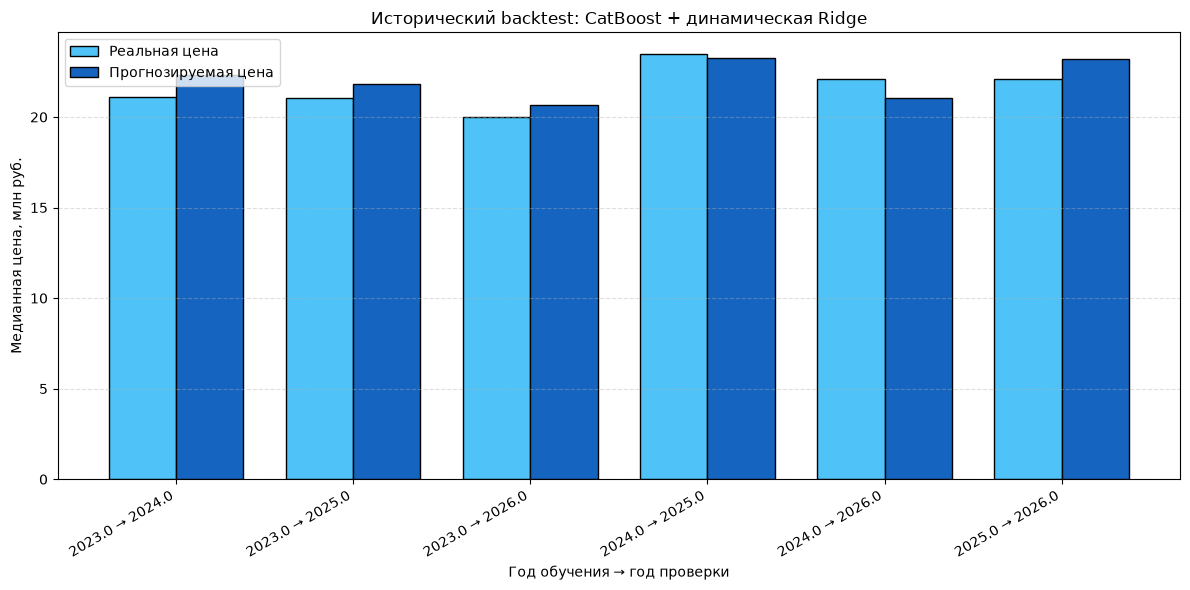

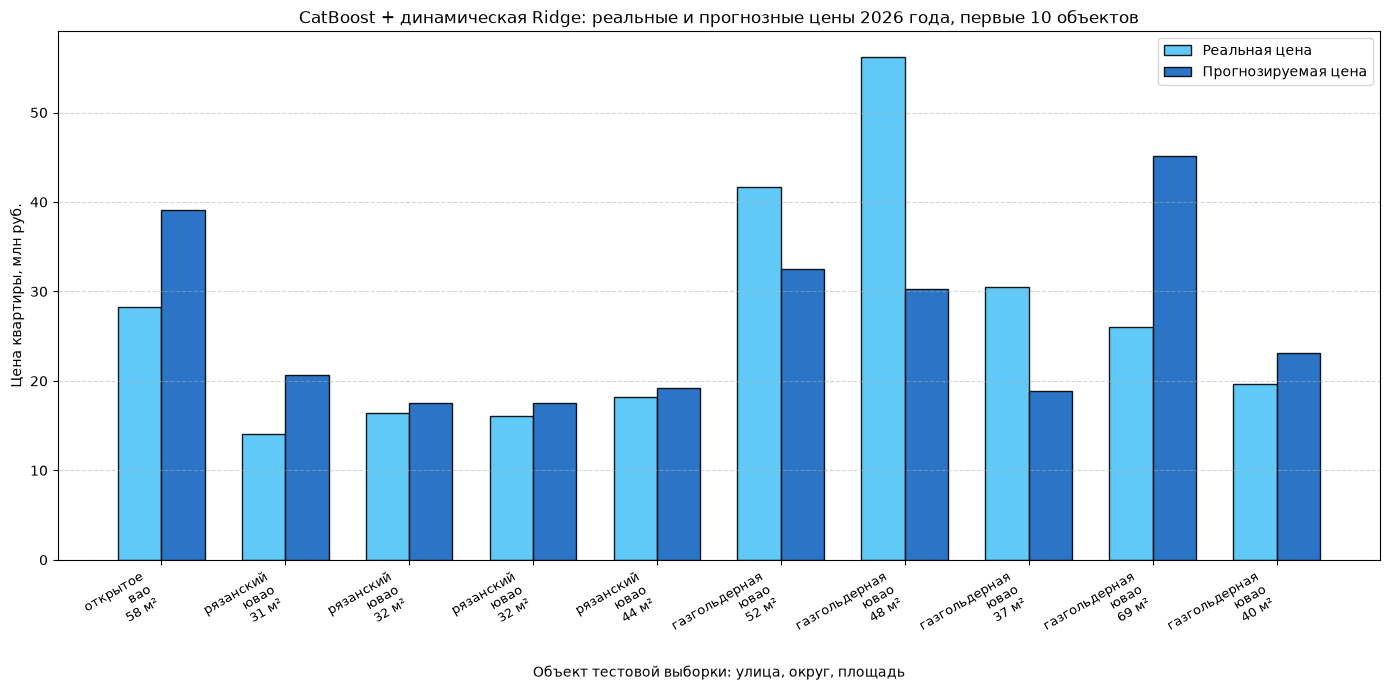

,"MAE, млн руб.","RMSE, млн руб.","MAPE, %",R²,"Accuracy, %"
0,9.05,11.99,30.48,0.11,69.52


Средняя абсолютная ошибка: 9.05 млн руб.
Максимальная абсолютная ошибка: 25.98 млн руб.
Средняя ошибка со знаком (факт − прогноз): 0.31 млн руб.
Средняя относительная абсолютная ошибка: 30.48%
Общая точность (100% − MAPE): 69.52%


In [5]:
import matplotlib.pyplot as plt
from sklearn.utils.validation import check_is_fitted
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BACKTEST_HORIZON = 5
BACKTEST_MIN_DEALS = 1000
BACKTEST_BASE_YEAR = 2026

def prepare_backtest_pair(train_raw, test_raw):
    """Готовит fold по правилам приложения; пороги выбросов оценивает только по train."""
    train = train_raw.copy()
    test = test_raw.copy()
    train["price_per_sqm"] = train["price"] / train["area"]
    test["price_per_sqm"] = test["price"] / test["area"]
    for column in ("price", "price_per_sqm"):
        mean = float(train[column].mean())
        std = float(train[column].std())
        lower, upper = mean - 3 * std, mean + 3 * std
        train = train[train[column].between(lower, upper)].copy()
        test = test[test[column].between(lower, upper)].copy()

    def finalize(frame):
        frame = frame.copy()
        frame["_source_id"] = frame.index.astype(int)
        for col in CAT_COLS:
            frame[col] = frame[col].map(app_model.normalize_text)
        frame["wall_material_code"] = frame["wall_material_code"].str.replace(r"\.0+$", "", regex=True)
        for col in NUM_COLS + ["price"]:
            frame[col] = pd.to_numeric(frame[col], errors="coerce")
        frame = frame.dropna(subset=NUM_COLS + ["price", "period_year"]).copy()
        frame = frame[
            frame["period_year"].between(2023, 2026)
            & frame["year_build"].between(1800, 2027)
            & (frame["year_build"] <= frame["period_year"] + 1)
            & frame["floor"].between(1, 100)
            & frame["area"].between(25, 400)
            & frame["price"].between(7_000_000, 1_000_000_000)
        ].copy()
        frame["price_per_sqm"] = frame["price"] / frame["area"]
        frame = frame[frame["price_per_sqm"].between(50_000, 15_000_000)].copy()
        frame["period_year"] = frame["period_year"].astype(int)
        return frame.sort_values("period_start_date").reset_index(drop=True)

    return finalize(train), finalize(test)

available_years = sorted(clean_df["period_year"].dropna().astype(int).unique())
backtest_origins = [year for year in available_years if year < BACKTEST_BASE_YEAR]
backtest_rows = []
backtest_predictions = []

for origin_year in backtest_origins:
    train_raw = clean_df[clean_df["period_year"] <= origin_year].copy()
    target_years = [
        year for year in available_years
        if origin_year < year <= min(origin_year + BACKTEST_HORIZON, BACKTEST_BASE_YEAR)
    ]
    if len(train_raw) < 30:
        continue

    for target_year in target_years:
        test_raw = clean_df[clean_df["period_year"] == target_year].copy()
        if len(test_raw) < BACKTEST_MIN_DEALS:
            continue
        train_bt, test_bt = prepare_backtest_pair(train_raw, test_raw)
        if len(train_bt) < 30 or len(test_bt) < BACKTEST_MIN_DEALS:
            continue

        cat_bt = ApartmentEstimator(
            kind="cat", random_state=RANDOM_STATE, thread_count=3, **CATBOOST_PARAMS
        ).fit(train_bt[FEATURE_COLS], train_bt["price"].to_numpy(float))
        ridge_bt = ApartmentEstimator(
            kind="ridge_time", random_state=RANDOM_STATE, **RIDGE_PARAMS
        ).fit(train_bt[FEATURE_COLS], train_bt["price"].to_numpy(float))

        X_target = test_bt[FEATURE_COLS].copy()
        X_origin = X_target.copy()
        X_origin["period_year"] = origin_year
        X_target["period_year"] = target_year
        cat_base_price = cat_bt.predict(X_origin)
        ridge_origin_price = ridge_bt.predict(X_origin)
        ridge_target_price = ridge_bt.predict(X_target)
        prediction = cat_base_price * (ridge_target_price / ridge_origin_price)
        actual = test_bt["price"].to_numpy(float)
        errors = prediction - actual
        ape = np.abs(errors) / np.maximum(actual, 1.0) * 100

        backtest_rows.append({
            "Год обучения до": origin_year,
            "Год проверки": target_year,
            "Горизонт, лет": target_year - origin_year,
            "Сделок в тесте": len(test_bt),
            "Фактическая медиана, млн руб.": float(np.median(actual) / 1e6),
            "Прогнозная медиана, млн руб.": float(np.median(prediction) / 1e6),
            "MAE, млн руб.": float(mean_absolute_error(actual, prediction) / 1e6),
            "RMSE, млн руб.": float(np.sqrt(mean_squared_error(actual, prediction)) / 1e6),
            "MAPE, %": float(ape.mean()),
            "Accuracy, %": float(100 - ape.mean()),
            "R²": float(r2_score(actual, prediction)) if len(actual) > 1 else np.nan,
        })
        backtest_predictions.append(pd.DataFrame({
            "origin_year": origin_year,
            "target_year": target_year,
            "real_mln": actual / 1e6,
            "predicted_mln": prediction / 1e6,
            "error_mln": (actual - prediction) / 1e6,
            "street": test_bt["street"].to_numpy(),
            "region": test_bt["region"].to_numpy(),
            "area": test_bt["area"].to_numpy(),
        }))
        print(f"Backtest {origin_year} → {target_year}: {len(test_bt):,} тестовых сделок")

backtest_table = pd.DataFrame(backtest_rows)
if backtest_table.empty:
    raise ValueError("Не удалось сформировать backtest: проверьте исторические годы и число сделок.")
display(backtest_table.round(2))

overall_backtest = pd.DataFrame([{
    "MAE, млн руб.": backtest_table["MAE, млн руб."].mean(),
    "RMSE, млн руб.": backtest_table["RMSE, млн руб."].mean(),
    "MAPE, %": backtest_table["MAPE, %"].mean(),
    "R²": backtest_table["R²"].mean(),
    "Accuracy, %": backtest_table["Accuracy, %"].mean(),
}])
display(overall_backtest.round(2))

# Гистограмма медианных фактических и прогнозных цен по проверенным периодам.
plot_periods = backtest_table.sort_values(["Год обучения до", "Год проверки"]).reset_index(drop=True)
x = np.arange(len(plot_periods))
width = 0.38
plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, plot_periods["Фактическая медиана, млн руб."], width,
        label="Реальная цена", color="#4FC3F7", edgecolor="black")
plt.bar(x + width / 2, plot_periods["Прогнозная медиана, млн руб."], width,
        label="Прогнозируемая цена", color="#1565C0", edgecolor="black")
plt.xticks(x, [f'{r["Год обучения до"]} → {r["Год проверки"]}' for _, r in plot_periods.iterrows()],
           rotation=30, ha="right")
plt.xlabel("Год обучения → год проверки")
plt.ylabel("Медианная цена, млн руб.")
plt.title("Исторический backtest: CatBoost + динамическая Ridge")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Сравнение цен первых 10 квартир для самой поздней проверки 2026 года.
comparison = pd.concat(backtest_predictions, ignore_index=True)
comparison_2026 = comparison[comparison["target_year"] == BACKTEST_BASE_YEAR].copy()
if not comparison_2026.empty:
    latest_origin = comparison_2026["origin_year"].max()
    comparison_2026 = comparison_2026[comparison_2026["origin_year"] == latest_origin].reset_index(drop=True)
    n = min(10, len(comparison_2026))
    sample = comparison_2026.head(n).copy()
    labels = [f'{s}\n{r}\n{a:.0f} м²'
              for s, r, a in zip(sample["street"], sample["region"], sample["area"])]
    x = np.arange(n)
    width = 0.35
    plt.figure(figsize=(14, 7))
    plt.bar(x - width / 2, sample["real_mln"], width, label="Реальная цена",
            alpha=0.9, edgecolor="black", color="#4FC3F7")
    plt.bar(x + width / 2, sample["predicted_mln"], width, label="Прогнозируемая цена",
            alpha=0.9, edgecolor="black", color="#1565C0")
    plt.xlabel("Объект тестовой выборки: улица, округ, площадь")
    plt.ylabel("Цена квартиры, млн руб.")
    plt.title(f"CatBoost + динамическая Ridge: реальные и прогнозные цены 2026 года, первые {n} объектов")
    plt.xticks(x, labels, rotation=30, ha="right", fontsize=9)
    plt.legend()
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    error = sample["real_mln"] - sample["predicted_mln"]
    ape_sample = np.abs(error) / np.maximum(sample["real_mln"], 1e-9) * 100
    display(pd.DataFrame([{
        "MAE, млн руб.": np.abs(error).mean(),
        "RMSE, млн руб.": np.sqrt(np.mean(error ** 2)),
        "MAPE, %": ape_sample.mean(),
        "R²": r2_score(sample["real_mln"], sample["predicted_mln"]) if n > 1 else np.nan,
        "Accuracy, %": 100 - ape_sample.mean(),
    }]).round(2))
    print(f"Средняя абсолютная ошибка: {np.abs(error).mean():.2f} млн руб.")
    print(f"Максимальная абсолютная ошибка: {np.abs(error).max():.2f} млн руб.")
    print(f"Средняя ошибка со знаком (факт − прогноз): {error.mean():.2f} млн руб.")
    print(f"Средняя относительная абсолютная ошибка: {ape_sample.mean():.2f}%")
    print(f"Общая точность (100% − MAPE): {100 - ape_sample.mean():.2f}%")
else:
    print("В датасете нет тестовых сделок 2026 года.")


### Сводные метрики для проверки 2026 года

Следующая таблица и статистика ошибок рассчитываются по всем тестовым сделкам 2026 года для самого позднего origin (обучение до 2025 года), а не только по десяти объектам на диаграмме.

In [6]:
actual_2026_all = comparison_2026["real_mln"].to_numpy(float) * 1e6
predicted_2026_all = comparison_2026["predicted_mln"].to_numpy(float) * 1e6
signed_error_2026 = actual_2026_all - predicted_2026_all
absolute_pct_error_2026 = (
    np.abs(signed_error_2026) / np.maximum(actual_2026_all, 1.0) * 100
)
mape_2026 = float(absolute_pct_error_2026.mean())
metrics_2026 = pd.DataFrame([{
    "MAE, млн руб.": mean_absolute_error(actual_2026_all, predicted_2026_all) / 1e6,
    "RMSE, млн руб.": np.sqrt(mean_squared_error(actual_2026_all, predicted_2026_all)) / 1e6,
    "MAPE, %": mape_2026,
    "R²": r2_score(actual_2026_all, predicted_2026_all),
    "Accuracy, %": 100 - mape_2026,
}])
display(metrics_2026.round(2))
print(f"Объектов в проверке 2026 года: {len(actual_2026_all):,}")
print(f"Средняя абсолютная ошибка: {np.abs(signed_error_2026).mean() / 1e6:.2f} млн руб.")
print(f"Максимальная абсолютная ошибка: {np.abs(signed_error_2026).max() / 1e6:.2f} млн руб.")
print(f"Средняя ошибка со знаком (факт − прогноз): {signed_error_2026.mean() / 1e6:.2f} млн руб.")
print(f"Средняя относительная абсолютная ошибка: {mape_2026:.2f}%")
print(f"Общая точность (100% − MAPE): {100 - mape_2026:.2f}%")

,"MAE, млн руб.","RMSE, млн руб.","MAPE, %",R²,"Accuracy, %"
0,6.36,9.57,22.47,0.54,77.53


Объектов в проверке 2026 года: 15,489
Средняя абсолютная ошибка: 6.36 млн руб.
Максимальная абсолютная ошибка: 60.06 млн руб.
Средняя ошибка со знаком (факт − прогноз): 0.15 млн руб.
Средняя относительная абсолютная ошибка: 22.47%
Общая точность (100% − MAPE): 77.53%


## 6. Финальное обучение и сохранение файла

После backtest CatBoost обучается на всех доступных очищенных данных, включая 2026 год. Динамическая Ridge обучается на данных до базового 2026 года. Обе обученные модели и параметры записываются в `Prognosis_model.joblib`.

In [ ]:
X_price = model_df[FEATURE_COLS].copy()
y_price = model_df["price"].to_numpy(float)
price_model = ApartmentEstimator(
    kind="cat", random_state=RANDOM_STATE, thread_count=3, **CATBOOST_PARAMS
).fit(X_price, y_price)

trend_df = model_df[model_df["period_year"] < FINAL_BASE_YEAR].copy()
trend_model = ApartmentEstimator(
    kind="ridge_time", random_state=RANDOM_STATE, **RIDGE_PARAMS
).fit(trend_df[FEATURE_COLS], trend_df["price"].to_numpy(float))

bundle = {
    "price_model": price_model,
    "trend_model": trend_model,
    "selected_model": "CatBoost",
    "base_year": FINAL_BASE_YEAR,
    "source_file": DATA_PATH.name,
    "version": "catboost-base_dynamic-ridge-growth-v1",
    "price_model_params": CATBOOST_PARAMS,
    "trend_model_params": RIDGE_PARAMS,
}
ApartmentEstimator.__module__ = app_model.__name__
app_model.ApartmentEstimator = ApartmentEstimator
joblib.dump(bundle, BUNDLE_PATH, compress=3)
print("Trained models saved to:", BUNDLE_PATH)
print(f"File size: {BUNDLE_PATH.stat().st_size:,} bytes")

## 7. Проверка сохранённого bundle

Файл повторно загружается с диска. Проверяется наличие обученных CatBoost и динамической Ridge, а также базового года.

In [ ]:
loaded = joblib.load(BUNDLE_PATH)
print("Bundle keys:", sorted(loaded.keys()))
print("Base-price model:", loaded["price_model"].kind)
print("Trend model:", loaded["trend_model"].kind)
print("Base year:", loaded["base_year"])